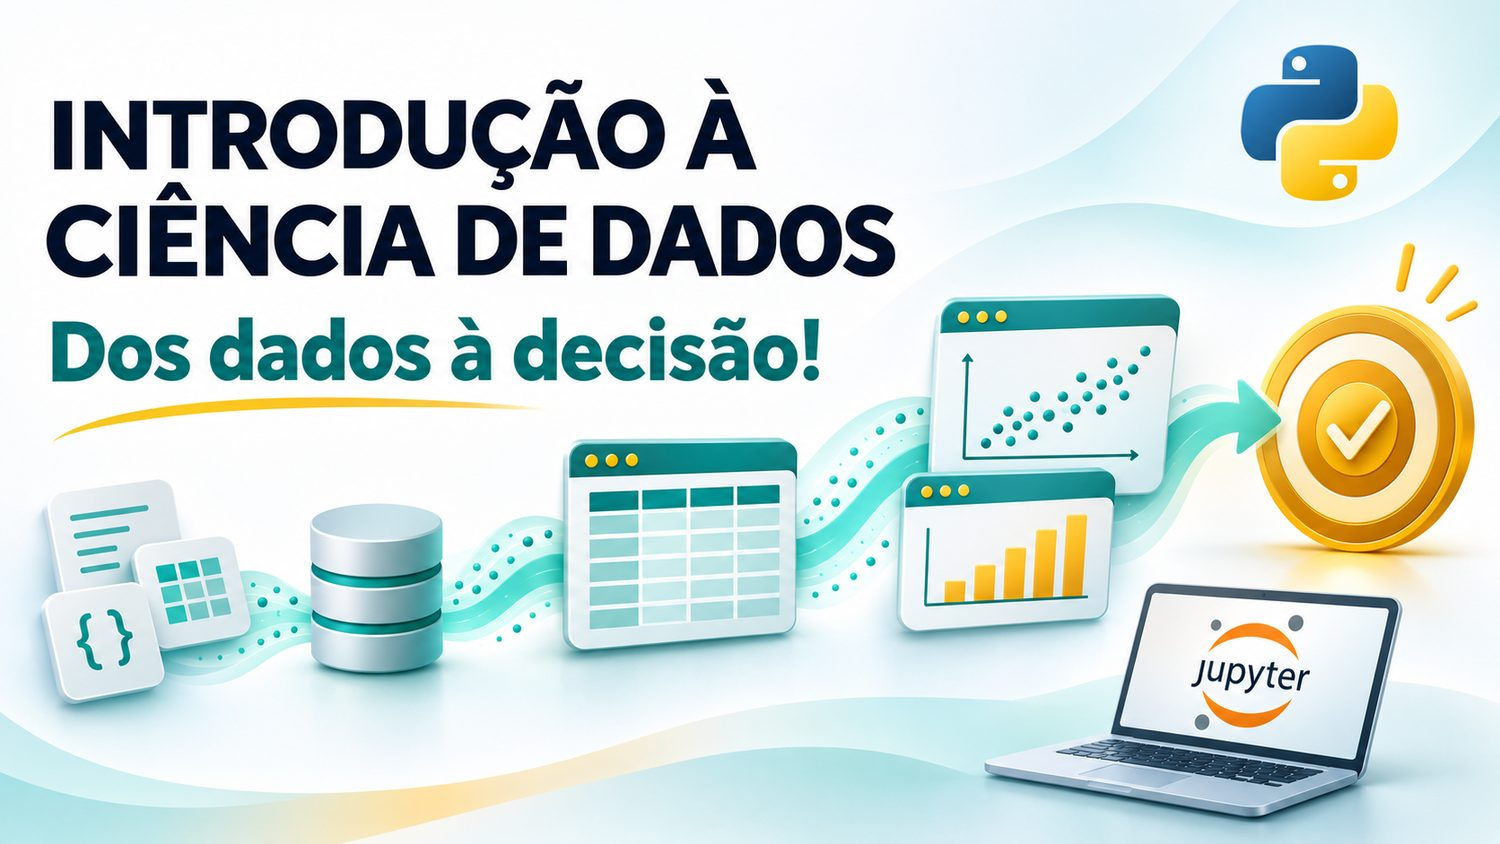

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ricardoluizdasilva/mestrado_ai_estudos/blob/main/Introdu%C3%A7%C3%A3o%20%C3%A0%20Ci%C3%AAncia%20de%20Dados/tutorial_ciencia_dados/modulo_4_preparar_os_dados/03_Valores_em_Falta_e_Imputacao.ipynb)

# Capítulo 3 – Valores em falta e imputação

Quase todos os modelos recusam uma tabela com células vazias. É preciso decidir o que fazer com elas, e nenhuma opção é neutra: remover linhas deita fora informação, e preencher inventa-a. Este capítulo mostra as opções, o que cada uma faz aos dados e ao modelo, e a regra que evita que o preenchimento se torne uma fuga de informação.

> **Objetivos:** medir quanto falta e onde; distinguir três mecanismos de falta e o efeito de cada um; comparar remover, preencher com um valor fixo, preencher por grupo e acrescentar um indicador de falta; avaliar o efeito de cada opção na distribuição e no erro do modelo; aprender os valores de preenchimento só no treino.

**Pré-requisitos:** capítulos 1 e 2 deste módulo, e o capítulo 4 do módulo 2 (qualidade dos dados).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch, FancyBboxPatch

# Cores usadas em todo o tutorial (sempre com o mesmo significado)
AZUL, VERDE, VIOLETA, LARANJA = "#2a78d6", "#1baf7a", "#6250d6", "#eb6834"
BOM, MAU, AVISO, CINZA, TINTA = "#0ca30c", "#d03b3b", "#fab219", "#b4bdc8", "#131c26"

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold",
                     "axes.titlelocation": "left"})


def tela(largura, altura, tamanho=(10, 3)):
    """Cria uma figura vazia, sem eixos, para desenhar esquemas."""
    fig, ax = plt.subplots(figsize=tamanho)
    ax.set_xlim(0, largura)
    ax.set_ylim(0, altura)
    ax.axis("off")
    return fig, ax


def caixa(ax, x, y, largura, altura, texto, cor, tamanho=10, negrito=False):
    """Desenha uma caixa arredondada com texto centrado."""
    ax.add_patch(FancyBboxPatch((x, y), largura, altura, boxstyle="round,pad=0.02,rounding_size=0.1",
                                fc=cor + "30", ec=cor, lw=1.6))
    ax.text(x + largura / 2, y + altura / 2, texto, ha="center", va="center", color=TINTA,
            fontsize=tamanho, linespacing=1.45, fontweight="bold" if negrito else "normal")


def seta(ax, inicio, fim, cor="#465463", **opcoes):
    """Desenha uma seta entre dois pontos."""
    opcoes.setdefault("arrowstyle", "-|>")
    ax.add_patch(FancyArrowPatch(inicio, fim, mutation_scale=14, color=cor, lw=1.5, **opcoes))

In [2]:
def gerar_carros(n=3000, semente=17):
    """Gera anúncios de carros usados de um stand fictício (dados sintéticos; as marcas são inventadas)."""
    rng = np.random.default_rng(semente)
    segmentos = {"citadino": (11000, 75), "utilitário": (15000, 100), "familiar": (21000, 130),
                 "SUV": (27000, 150), "monovolume": (23000, 125), "desportivo": (38000, 240)}
    marcas = {"Alba": 1.00, "Boreal": 0.92, "Cimo": 1.08, "Dueto": 0.95, "Estela": 1.30, "Faro": 1.00,
              "Gávea": 0.88, "Hera": 1.45, "Ípsilon": 1.05, "Jade": 0.97, "Kappa": 1.60, "Lume": 0.90}
    frequencia = np.array([18, 16, 14, 12, 9, 9, 7, 5, 4, 3, 2, 1], dtype=float)
    segmento = rng.choice(list(segmentos), n, p=[0.24, 0.28, 0.18, 0.18, 0.08, 0.04])
    marca = rng.choice(list(marcas), n, p=frequencia / frequencia.sum())
    ano = rng.integers(2008, 2026, n)
    idade = 2026 - ano
    km = (idade * 14000 * rng.lognormal(0, 0.35, n) + rng.uniform(500, 6000, n)).round(-2)
    potencia = np.array([segmentos[s][1] for s in segmento]) * rng.normal(1, 0.12, n)
    prob_eletrico = np.clip((ano - 2016) * 0.03, 0, 0.25)
    sorteio = rng.random(n)
    combustivel = np.where(sorteio < prob_eletrico, "elétrico", np.where(sorteio < prob_eletrico + 0.15, "híbrido",
                           np.where(sorteio < prob_eletrico + 0.55, "gasóleo", "gasolina")))
    caixa_velocidades = np.where(rng.random(n) < 0.25 + 0.4 * (combustivel == "elétrico"), "automática", "manual")
    niveis = np.array(["mau", "razoável", "bom", "excelente"])
    estado = niveis[np.clip(rng.normal(2.2 - 0.06 * idade, 0.8, n).round(), 0, 3).astype(int)]
    fator_estado = pd.Series(estado).map({"mau": 0.78, "razoável": 0.92, "bom": 1.0, "excelente": 1.08}).to_numpy()
    ruido = rng.lognormal(0, 0.10, n)                      # o que o preço tem de «caro» ou de «barato» sem explicação
    preco = (np.array([segmentos[s][0] for s in segmento]) * np.array([marcas[m] for m in marca])
             * np.exp(-0.085 * idade) * np.exp(-km / 420000) * fator_estado
             * np.where(caixa_velocidades == "automática", 1.08, 1.0)
             * np.where(combustivel == "elétrico", 1.25, np.where(combustivel == "híbrido", 1.12, 1.0))
             * (potencia / np.array([segmentos[s][1] for s in segmento])) ** 0.4 * ruido)
    carros = pd.DataFrame({
        "marca": marca, "segmento": segmento, "ano": ano, "km": km, "potencia_cv": potencia.round(),
        "combustivel": combustivel, "caixa": caixa_velocidades, "estado": estado,
        "cor": rng.choice(["branco", "cinzento", "preto", "azul", "vermelho"], n), "preco": preco.round(-1)})
    nivel = pd.Series(estado).map({"mau": 0, "razoável": 1, "bom": 2, "excelente": 3}).to_numpy()
    z = (-0.2 + 0.75 * (nivel - 1.5) - 0.07 * idade + 0.7 * np.isin(segmento, ["SUV", "utilitário"])
         + 0.5 * (caixa_velocidades == "automática") - 5 * np.log(ruido))
    carros["vendido_30_dias"] = rng.random(n) < 1 / (1 + np.exp(-z))
    # Valores em falta: quem tem muitos quilómetros «esquece-se» mais vezes de os indicar
    carros.loc[rng.random(n) < 0.03 + 0.25 * (km > np.quantile(km, 0.8)), "km"] = np.nan
    carros.loc[rng.random(n) < 0.06, "potencia_cv"] = np.nan
    carros.loc[rng.random(n) < 0.05, "estado"] = np.nan
    return carros


carros = gerar_carros()
carros.head()

,marca,segmento,ano,km,potencia_cv,combustivel,caixa,estado,cor,preco,vendido_30_dias
0,Boreal,SUV,2019,127500.0,199.0,híbrido,automática,razoável,cinzento,15250.0,False
1,Gávea,citadino,2012,171200.0,67.0,gasolina,manual,bom,azul,1630.0,False
2,Gávea,familiar,2018,123900.0,116.0,gasóleo,automática,bom,preto,6670.0,True
3,Cimo,utilitário,2009,239000.0,98.0,gasolina,manual,bom,cinzento,2350.0,False
4,Boreal,citadino,2016,122600.0,51.0,gasóleo,manual,bom,branco,3080.0,False


## Quanto falta, e onde

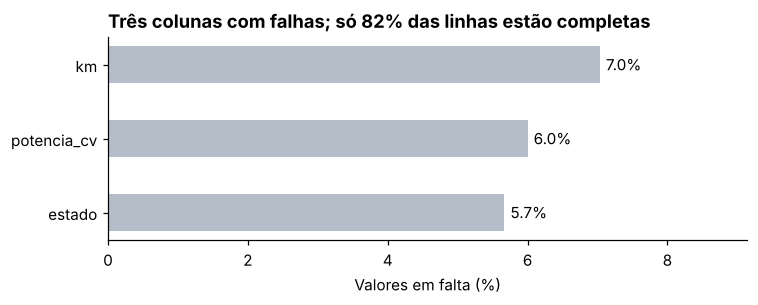

In [3]:
em_falta = carros.isna().mean().mul(100).sort_values(ascending=False)
em_falta = em_falta[em_falta > 0]
linhas_completas = carros.notna().all(axis=1).mean() * 100

fig, ax = plt.subplots(figsize=(7.5, 2.4))
barras = ax.barh(em_falta.index, em_falta, color=CINZA, height=0.5)
ax.bar_label(barras, fmt="%.1f%%", padding=4)
ax.invert_yaxis()
ax.set_xlim(0, em_falta.max() * 1.3)
ax.set_xlabel("Valores em falta (%)")
ax.set_title(f"Três colunas com falhas; só {linhas_completas:.0f}% das linhas estão completas")
plt.show()

Nenhuma coluna tem mais de 7% de valores em falta, mas as falhas não coincidem: somadas, deixam incompleta quase uma linha em cada cinco. É o primeiro custo de remover linhas: perde-se muito mais do que a percentagem de cada coluna sugere.

Antes de decidir, a pergunta do módulo 2: **porque faltam?**

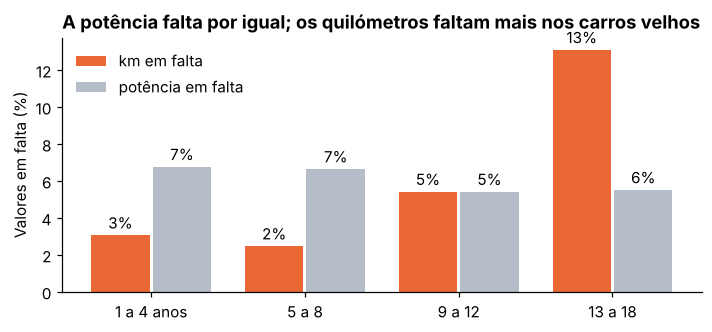

In [4]:
carros["idade"] = 2026 - carros["ano"]
falta_km = carros["km"].isna()
por_idade = carros.groupby(pd.cut(carros["idade"], [0, 4, 8, 12, 18]), observed=True)[["km", "potencia_cv"]].agg(lambda s: s.isna().mean() * 100)
por_idade.index = ["1 a 4 anos", "5 a 8", "9 a 12", "13 a 18"]

x = np.arange(4)
fig, ax = plt.subplots(figsize=(7.5, 3))
b1 = ax.bar(x - 0.2, por_idade["km"], 0.38, color=LARANJA, label="km em falta")
b2 = ax.bar(x + 0.2, por_idade["potencia_cv"], 0.38, color=CINZA, label="potência em falta")
ax.bar_label(b1, fmt="%.0f%%", padding=2)
ax.bar_label(b2, fmt="%.0f%%", padding=2)
ax.set_xticks(x, por_idade.index)
ax.set_ylabel("Valores em falta (%)")
ax.set_title("A potência falta por igual; os quilómetros faltam mais nos carros velhos")
ax.legend(frameon=False)
plt.show()

A potência falta mais ou menos na mesma proporção em todas as idades. Os quilómetros faltam muito mais nos carros antigos. Não é difícil imaginar porquê: quem tem um carro com muitos quilómetros tem menos vontade de os escrever no anúncio.

## Três mecanismos de falta

A razão pela qual um valor falta decide o estrago que a falta faz.

| Mecanismo | A falta depende de… | Exemplo | Consequência de ignorar as linhas |
| --- | --- | --- | --- |
| **Completamente ao acaso** | nada | Um campo que o sistema não gravou em 5% dos anúncios | Perdem-se dados, mas os que ficam são representativos |
| **Ao acaso, dado o que se observa** | outras variáveis que conhecemos | Os anúncios de carros antigos omitem mais os quilómetros | Enviesamento, corrigível usando essas variáveis |
| **Não ao acaso** | o próprio valor que falta | Omite-se o valor *porque* é alto | Enviesamento que os dados, sozinhos, não deixam corrigir |

Os nomes técnicos são MCAR, MAR e MNAR (*missing completely at random*, *missing at random* e *missing not at random*).

Nos dados reais nunca se sabe ao certo qual é o mecanismo, porque não se veem os valores que faltam. Numa simulação, sim. Vamos pegar nos carros com quilómetros conhecidos e apagar 25% de três maneiras.

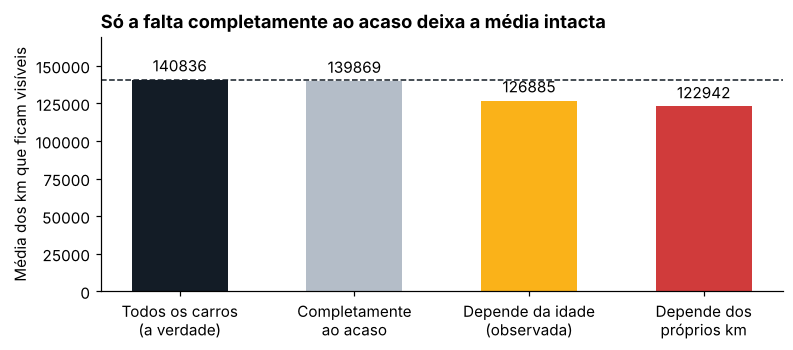

In [5]:
rng = np.random.default_rng(0)
conhecidos = carros.dropna(subset=["km"]).copy()
km = conhecidos["km"]
posicao_idade = conhecidos["idade"].rank(pct=True)
posicao_km = km.rank(pct=True)

apagar = {"Completamente\nao acaso": rng.random(len(km)) < 0.25,
          "Depende da idade\n(observada)": rng.random(len(km)) < 0.5 * posicao_idade ** 2 + 0.08,
          "Depende dos\npróprios km": rng.random(len(km)) < 0.5 * posicao_km ** 2 + 0.08}

fig, ax = plt.subplots(figsize=(8, 3))
medias = [km.mean()] + [km[~mascara].mean() for mascara in apagar.values()]
barras = ax.bar(["Todos os carros\n(a verdade)"] + list(apagar), medias, color=[TINTA, CINZA, AVISO, MAU], width=0.55)
ax.bar_label(barras, fmt="%.0f", padding=3)
ax.axhline(km.mean(), color=TINTA, ls="--", lw=1)
ax.set_ylabel("Média dos km que ficam visíveis")
ax.set_ylim(0, km.mean() * 1.2)
ax.set_title("Só a falta completamente ao acaso deixa a média intacta")
plt.show()

Quando a falta é completamente ao acaso, a média dos valores visíveis é praticamente a verdadeira. Nos outros dois casos, os carros com mais quilómetros desapareceram mais vezes, e o que resta parece um parque automóvel mais novo do que é.

A diferença entre o segundo e o terceiro caso está no que se pode fazer. No segundo, a idade está na tabela e explica a falta: preenchendo com base na idade, corrige-se boa parte do erro. No terceiro, a falta depende do próprio valor escondido, e só informação de fora (uma inspeção, o livro de revisões) o resolve.

## As opções

| Opção | O que faz | Custo |
| --- | --- | --- |
| **Remover as linhas** | Fica só com os casos completos | Perde dados; enviesa, se a falta não for ao acaso; **não permite prever casos novos incompletos** |
| **Remover a coluna** | Desiste da variável | Perde toda a informação que ela tinha |
| **Preencher com um valor fixo** | Média, mediana ou moda da coluna | Reduz a dispersão; ignora as outras variáveis |
| **Preencher por grupo** | Mediana de carros parecidos | Mais trabalho; precisa de grupos com dados suficientes |
| **Acrescentar um indicador** | Uma coluna nova que diz «faltava» | Mais uma coluna; guarda a informação de que o valor faltava |
| **Preencher com um modelo** | Prevê o valor em falta a partir das outras colunas | Mais complexo; pode dar uma falsa sensação de precisão |

Ao preenchimento chama-se **imputação**.

O terceiro custo da primeira linha é o que mais se esquece. Um modelo treinado só com linhas completas não sabe o que fazer quando chega ao stand um carro sem os quilómetros indicados, e isso acontece em 7% dos carros. Remover linhas resolve o treino e deixa o problema para o dia em que o modelo é usado.

### O que a imputação faz à distribuição

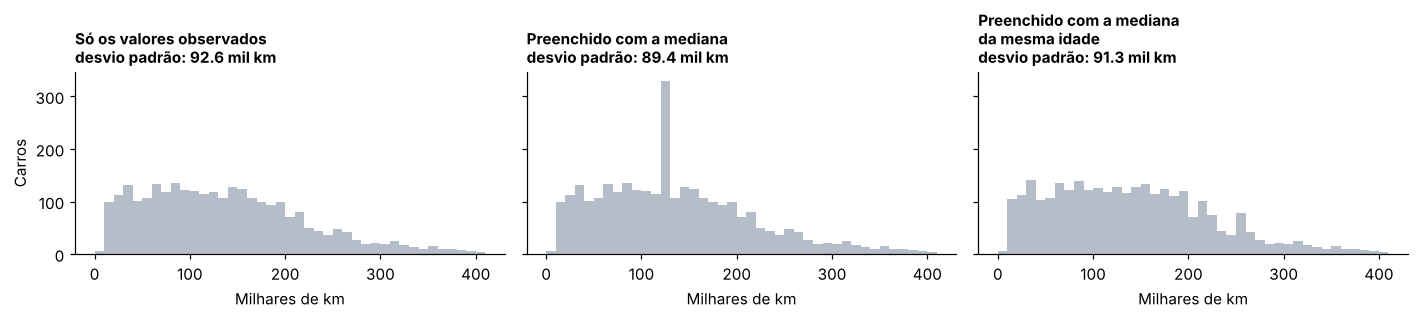

In [6]:
mediana = carros["km"].median()
por_grupo = carros.groupby("idade")["km"].transform("median")
versoes = {"Só os valores observados": carros["km"].dropna(),
           "Preenchido com a mediana": carros["km"].fillna(mediana),
           "Preenchido com a mediana\nda mesma idade": carros["km"].fillna(por_grupo)}

fig, eixos = plt.subplots(1, 3, figsize=(13, 3), sharey=True)
for ax, (nome, valores) in zip(eixos, versoes.items()):
    ax.hist(valores / 1000, bins=np.arange(0, 420, 10), color=CINZA)
    ax.set_title(f"{nome}\ndesvio padrão: {valores.std() / 1000:.1f} mil km", fontsize=10)
    ax.set_xlabel("Milhares de km")
eixos[0].set_ylabel("Carros")
plt.tight_layout()
plt.show()

Preencher tudo com a mediana cria uma **barra artificial**: de repente há mais de duzentos carros com exatamente os mesmos quilómetros. O desvio padrão desce, porque se acrescentaram valores todos iguais ao centro.

Preencher com a mediana dos carros da mesma idade espalha os valores imputados por várias barras e conserva melhor a forma. Continua a ser uma invenção, mas uma invenção mais plausível: a um carro de 15 anos atribui-se a quilometragem típica de um carro de 15 anos, e não a de um carro médio.

### O indicador de falta

Vimos que os quilómetros faltam mais quando são altos. Então o facto de faltarem **é informação**: um anúncio sem quilómetros é, em média, de um carro mais usado, e provavelmente mais barato do que os outros da mesma idade.

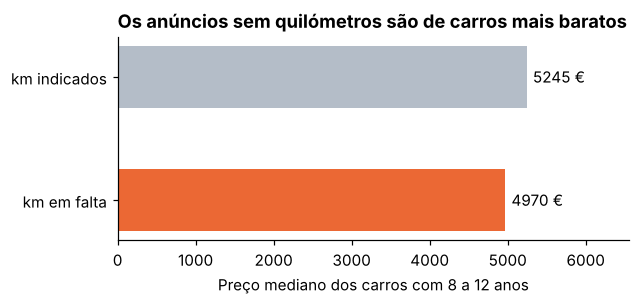

In [7]:
recentes = carros[carros["idade"].between(8, 12)]
comparacao = recentes.groupby(recentes["km"].isna())["preco"].median()

fig, ax = plt.subplots(figsize=(6, 2.4))
barras = ax.barh(["km indicados", "km em falta"], comparacao.values, color=[CINZA, LARANJA], height=0.5)
ax.bar_label(barras, fmt="%.0f €", padding=4)
ax.invert_yaxis()
ax.set_xlim(0, comparacao.max() * 1.25)
ax.set_xlabel("Preço mediano dos carros com 8 a 12 anos")
ax.set_title("Os anúncios sem quilómetros são de carros mais baratos")
plt.show()

A diferença é pequena, mas vai no sentido esperado. Se preenchermos os quilómetros e não dissermos mais nada, o modelo trata esses carros como carros normais. Uma coluna adicional `km_em_falta`, com 1 onde o valor faltava, permite-lhe aprender o desconto, se ele existir.

## O efeito no modelo

Vamos comparar cinco estratégias com o mesmo modelo (uma regressão linear) e o mesmo conjunto de teste. Em todas, o que se aprende para preencher vem **só do treino**.

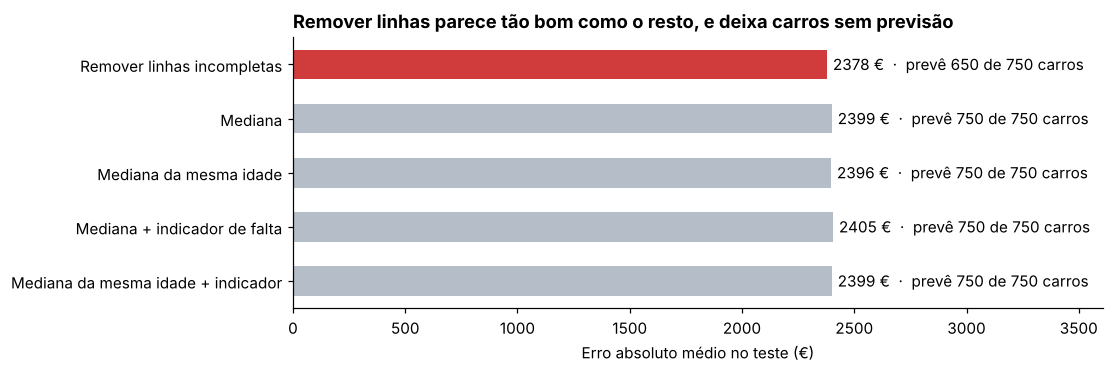

In [8]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split

atributos = ["idade", "km", "potencia_cv"]
treino, teste = train_test_split(carros, test_size=0.25, random_state=0)


def avaliar(preparar):
    """Treina e testa uma regressão linear; `preparar` recebe (tabela, treino) e devolve os atributos prontos."""
    X_treino, X_teste = preparar(treino, treino), preparar(teste, treino)
    modelo = LinearRegression().fit(X_treino, treino.loc[X_treino.index, "preco"])
    return mean_absolute_error(teste.loc[X_teste.index, "preco"], modelo.predict(X_teste)), len(X_teste)


def remover_linhas(tabela, referencia):
    return tabela[atributos].dropna()


def com_mediana(tabela, referencia):
    return tabela[atributos].fillna(referencia[atributos].median())


def com_mediana_por_idade(tabela, referencia):
    por_idade = referencia.groupby("idade")[["km", "potencia_cv"]].median()
    X = tabela[atributos].copy()
    for coluna in ["km", "potencia_cv"]:
        X[coluna] = X[coluna].fillna(tabela["idade"].map(por_idade[coluna]))
    return X.fillna(referencia[atributos].median())


def com_indicador(tabela, referencia):
    return com_mediana(tabela, referencia).assign(km_em_falta=tabela["km"].isna().astype(int))


def por_idade_com_indicador(tabela, referencia):
    return com_mediana_por_idade(tabela, referencia).assign(km_em_falta=tabela["km"].isna().astype(int))


estrategias = {"Remover linhas incompletas": remover_linhas, "Mediana": com_mediana, "Mediana da mesma idade": com_mediana_por_idade,
               "Mediana + indicador de falta": com_indicador, "Mediana da mesma idade + indicador": por_idade_com_indicador}
resultados = {nome: avaliar(funcao) for nome, funcao in estrategias.items()}

fig, ax = plt.subplots(figsize=(9.5, 3.2))
cores = [MAU] + [CINZA] * 4
barras = ax.barh(list(resultados), [r[0] for r in resultados.values()], color=cores, height=0.55)
ax.bar_label(barras, labels=[f"{erro:.0f} €  ·  prevê {n} de {len(teste)} carros" for erro, n in resultados.values()], padding=4)
ax.invert_yaxis()
ax.set_xlim(0, max(r[0] for r in resultados.values()) * 1.5)
ax.set_xlabel("Erro absoluto médio no teste (€)")
ax.set_title("Remover linhas parece tão bom como o resto, e deixa carros sem previsão")
plt.show()

Três leituras:

- **Remover linhas** dá um erro parecido com o das outras opções, mas não é comparável: só foi medido nos carros de teste completos. Os restantes ficaram sem preço proposto. No stand, isso não é aceitável.
- As quatro formas de **imputar** preveem todos os carros.
- As diferenças entre elas são de poucos euros, muito menos do que a variação do erro de uma divisão para outra (capítulo 2). Com 6% a 7% de valores em falta e um modelo simples, a forma de preencher pesa muito menos do que a escolha dos atributos.

A lição geral: a imputação raramente salva um modelo e raramente o estraga, desde que seja feita com cuidado. O que estraga é remover linhas sem pensar, ou imputar de forma que deixe passar informação do teste.

## A regra: aprender no treino, aplicar no teste

A mediana usada para preencher é um número **aprendido a partir dos dados**, tal como os parâmetros do modelo. Por isso segue a mesma regra do capítulo 2: aprende-se só com o treino.

In [9]:
from sklearn.impute import SimpleImputer

imputador = SimpleImputer(strategy="median", add_indicator=True)
imputador.fit(treino[atributos])                                   # aprende as medianas no treino
X_treino = imputador.transform(treino[atributos])                  # aplica ao treino
X_teste = imputador.transform(teste[atributos])                    # e aplica AS MESMAS medianas ao teste

print("Medianas aprendidas no treino:", dict(zip(atributos, imputador.statistics_.tolist())))
print("Colunas produzidas:", list(imputador.get_feature_names_out()))
print("Formas:", X_treino.shape, X_teste.shape)

Medianas aprendidas no treino: {'idade': 10.0, 'km': 125750.0, 'potencia_cv': 110.0}
Colunas produzidas: ['idade', 'km', 'potencia_cv', 'missingindicator_km', 'missingindicator_potencia_cv']
Formas: (2250, 5) (750, 5)


O `SimpleImputer` separa as duas operações: `fit` calcula as medianas, `transform` aplica-as. Com `add_indicator=True`, acrescenta uma coluna de indicador por cada atributo que tinha valores em falta no treino.

O erro a evitar é este:

```python
carros["km"] = carros["km"].fillna(carros["km"].median())    # ERRADO: a mediana usa os carros de teste
treino, teste = train_test_split(carros)
```

A mediana foi calculada com todos os carros, incluindo os que depois vão para o teste. Com uma mediana de três mil carros, o efeito no resultado é minúsculo, e é por isso que o erro passa despercebido. Com operações mais agressivas feitas antes da divisão (escolher atributos, afinar escalas, preencher com um modelo), o efeito pode ser grande. O capítulo 6 mostra um caso em que cria um modelo que parece funcionar e não funciona.

## Variáveis categóricas

O estado do carro falta em 5% dos anúncios. Há duas opções simples.

In [10]:
moda = treino["estado"].mode()[0]
print("Categoria mais frequente no treino:", moda, "\n")
print(pd.DataFrame({"original": carros["estado"].value_counts(dropna=False),
                    "com a moda": carros["estado"].fillna(moda).value_counts(),
                    "categoria própria": carros["estado"].fillna("não indicado").value_counts()}).fillna(0).astype(int))

Categoria mais frequente no treino: bom 

              original  com a moda  categoria própria
estado                                               
bom               1122        1292               1122
excelente          425         425                425
mau                294         294                294
não indicado         0           0                170
razoável           989         989                989
NaN                170           0                  0


Preencher com a **moda** mistura os carros sem estado indicado com os que estão em bom estado. Criar uma **categoria própria** («não indicado») mantém-nos à parte, e é o equivalente, para categorias, do indicador de falta. É quase sempre a melhor opção: não inventa nada, e deixa o modelo aprender se «não indicar o estado» quer dizer alguma coisa.

## Um guia de decisão

| Situação | Sugestão |
| --- | --- |
| Faltam muito poucos valores, ao acaso, e há muitos dados | Remover linhas é aceitável, **se** os casos novos chegarem sempre completos |
| Falta numa variável numérica | Mediana (ou mediana por grupo) **e** indicador de falta |
| Falta numa variável categórica | Uma categoria «não indicado» |
| Falta a maior parte da coluna | Considerar remover a coluna, ou ficar só com o indicador |
| A falta depende do próprio valor | Indicador de falta; procurar a informação noutra fonte; dizer que a conclusão tem reservas |
| Falta no **alvo** | Essas linhas não servem para treinar nem para testar: removem-se |

Em todos os casos: decide-se olhando para o treino, aprende-se no treino e aplica-se ao teste.

## Exercícios

### `Exercício 1` – Que mecanismo?

Indica o mecanismo de falta mais provável em cada caso:

1. Num inquérito, as pessoas com rendimentos mais altos deixam mais vezes em branco a pergunta sobre o rendimento.
2. Um sensor de temperatura perde leituras quando a rede sem fios falha.
3. Os homens respondem menos do que as mulheres a uma pergunta sobre saúde, e o sexo de quem responde é conhecido.
4. Uma balança deixa de registar acima de 150 kg.

<details>
<summary><b>Ver uma solução possível</b></summary>

1. Não ao acaso: depende do próprio valor.
2. Completamente ao acaso, se as falhas de rede não tiverem relação com a temperatura.
3. Ao acaso, dado o que se observa: depende do sexo, que está registado.
4. Não ao acaso, e do pior tipo: faltam exatamente os valores mais altos.

</details>

### `Exercício 2` – Média ou mediana?

Preenche os quilómetros em falta com a média e com a mediana do treino. Os dois valores são muito diferentes? Qual escolhes, e porquê? (Lembra-te do capítulo 3 do módulo 3.)

In [11]:
# Escreve aqui o código do exercício 2

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
print(f"Média: {treino['km'].mean():.0f} | mediana: {treino['km'].median():.0f} | assimetria: {treino['km'].skew():.2f}")
```

A distribuição dos quilómetros tem cauda à direita, por isso a média fica acima da mediana. A mediana representa melhor o carro típico e não é arrastada por meia dúzia de carros com quilometragens enormes. Para variáveis assimétricas, a mediana é a escolha habitual.

</details>

### `Exercício 3` – O indicador ajuda?

Usa a função `avaliar` para comparar «mediana» e «mediana + indicador de falta» em 20 divisões diferentes de treino e teste. Em quantas o indicador ganha? A diferença é maior ou menor do que a variação entre divisões?

In [12]:
# Escreve aqui o código do exercício 3

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
diferencas = []
for semente in range(20):
    treino, teste = train_test_split(carros, test_size=0.25, random_state=semente)
    diferencas.append(avaliar(com_mediana)[0] - avaliar(com_indicador)[0])
treino, teste = train_test_split(carros, test_size=0.25, random_state=0)        # repõe a divisão original
print("O indicador ganha em", sum(d > 0 for d in diferencas), "de 20 divisões; ganho médio:", round(np.mean(diferencas)), "€")
```

O indicador ganha em 17 das 20 divisões, mas por cerca de 4 € em média, quando o erro ronda os 2 400 €. É uma melhoria real e minúscula, que uma só divisão não deixaria ver (na divisão do texto, o indicador até perde). Nestes dados, a falta dos quilómetros diz pouco que a idade não diga já. Em dados onde a falta é mais reveladora, o indicador pesa mais.

</details>

### `Exercício 4` – Imputar com vizinhos

O scikit-learn tem um `KNNImputer`, que preenche cada valor em falta com a média dos carros mais parecidos nas outras colunas. Usa-o (com `fit` no treino) e compara o erro do modelo com o das outras estratégias.

In [13]:
# Escreve aqui o código do exercício 4

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
from sklearn.impute import KNNImputer

imp = KNNImputer(n_neighbors=10).fit(treino[atributos])
modelo = LinearRegression().fit(imp.transform(treino[atributos]), treino["preco"])
print(round(mean_absolute_error(teste["preco"], modelo.predict(imp.transform(teste[atributos])))), "€")
```

O resultado fica perto do da mediana por idade: ambos usam carros parecidos para preencher. O `KNNImputer` tem o mesmo problema do KNN do capítulo 2 (as distâncias são dominadas pelos quilómetros, que estão noutra escala), o que nos leva ao capítulo seguinte.

</details>

## Verifica o que aprendeste

- [ ] Sei medir os valores em falta por coluna e por linha.
- [ ] Sei distinguir os três mecanismos de falta e a consequência de cada um.
- [ ] Sei porque remover linhas não resolve o problema no momento de prever.
- [ ] Sei o que a imputação com um valor fixo faz à distribuição.
- [ ] Sei para que serve um indicador de falta.
- [ ] Sei porque os valores de imputação se aprendem só no treino.
- [ ] Sei tratar valores em falta numa variável categórica.

## Leitura recomendada

- https://scikit-learn.org/stable/modules/impute.html
- https://en.wikipedia.org/wiki/Missing_data
- https://en.wikipedia.org/wiki/Imputation_(statistics)